In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/aymanalmadany/ham10000/__results__.html
/kaggle/input/notebooks/aymanalmadany/ham10000/pca_model.pkl
/kaggle/input/notebooks/aymanalmadany/ham10000/__notebook__.ipynb
/kaggle/input/notebooks/aymanalmadany/ham10000/__output__.json
/kaggle/input/notebooks/aymanalmadany/ham10000/custom.css
/kaggle/input/notebooks/aymanalmadany/ham10000/saved_models/best_cnn_model.keras
/kaggle/input/notebooks/aymanalmadany/ham10000/saved_models/best_resnet_model.keras
/kaggle/input/notebooks/aymanalmadany/ham10000/saved_models/best_resnet_finetuned.keras
/kaggle/input/notebooks/aymanalmadany/ham10000/__results___files/__results___61_12.png
/kaggle/input/notebooks/aymanalmadany/ham10000/__results___files/__results___76_0.png
/kaggle/input/notebooks/aymanalmadany/ham10000/__results___files/__results___62_3.png
/kaggle/input/notebooks/aymanalmadany/ham10000/__results___files/__results___98_4.png
/kaggle/input/notebooks/aymanalmadany/ham10000/__results___files/__results___112_3.png
/ka

In [2]:
print("Skin Lesion Classification Project")

import sys
print("Python version:", sys.version)

Skin Lesion Classification Project
Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [3]:

# STEP 3: Check our machine-learning environment

import sys
import importlib

print("Python version:", sys.version)
print("\nChecking required libraries...\n")

libraries = {
    "tensorflow": "TensorFlow",
    "numpy": "NumPy",
    "pandas": "Pandas",
    "sklearn": "Scikit-learn",
    "PIL": "Pillow",
    "matplotlib": "Matplotlib",
}

for module_name, library_name in libraries.items():
    try:
        module = importlib.import_module(module_name)
        version = getattr(module, "__version__", "installed")
        print(f"OK  {library_name}: {version}")
    except ImportError:
        print(f"MISSING  {library_name}")

print("\nEnvironment check complete!")


Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]

Checking required libraries...

OK  TensorFlow: 2.20.0
OK  NumPy: 2.1.3
OK  Pandas: 2.3.3
OK  Scikit-learn: 1.6.1
OK  Pillow: 12.3.0
OK  Matplotlib: 3.10.0

Environment check complete!


In [4]:

# project_check.py
# Skin Lesion Classification Project
# Step 4: Project setup verification

from pathlib import Path
import platform
import sys
PROJECT_NAME = "Skin Lesion Classification"
DATASET_NAME = "HAM10000"

CLASS_NAMES = [
    "akiec",
    "bcc",
    "bkl",
    "df",
    "mel",
    "nv",
    "vasc",
]

print("=" * 45)
print(PROJECT_NAME)
print("=" * 45)

print("Python version:", sys.version.split()[0])
print("Platform:", platform.system())
print("Dataset planned:", DATASET_NAME)

print("\nClassification categories:")
for index, class_name in enumerate(CLASS_NAMES, start=1):
    print(f"{index}. {class_name}")

print("\nProject setup check completed!")
print("This file does not train a model yet.")


Skin Lesion Classification
Python version: 3.13.15
Platform: Linux
Dataset planned: HAM10000

Classification categories:
1. akiec
2. bcc
3. bkl
4. df
5. mel
6. nv
7. vasc

Project setup check completed!
This file does not train a model yet.


In [5]:

# STEP 5: Inspect the attached HAM10000 dataset

from pathlib import Path
import pandas as pd

DATA_ROOT = Path("/kaggle/input")

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        "Kaggle input folder not found. Check your notebook environment."
    )

print("Searching for dataset files...\n")

csv_files = list(DATA_ROOT.rglob("HAM10000_metadata.csv"))

if not csv_files:
    print("Metadata CSV not found.")
    print("Check that you added the HAM10000 dataset as input.")
else:
    metadata_path = csv_files[0]
    print("Metadata file:")
    print(metadata_path)

    df = pd.read_csv(metadata_path)

    print("\nDataset shape:", df.shape)
    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nFirst five rows:")
    display(df.head())

    print("\nImages per category:")
    print(df["dx"].value_counts())

    print("\nSearching for image folders...")
    image_extensions = {".jpg", ".jpeg", ".png"}

    image_files = [
        p for p in DATA_ROOT.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    print("Image files found:", len(image_files))

    if image_files:
        print("\nExample image paths:")
        for path in image_files[:5]:
            print(path)


Searching for dataset files...

Metadata file:
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv

Dataset shape: (10015, 7)

Column names:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

First five rows:


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear



Images per category:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Searching for image folders...
Image files found: 20070

Example image paths:
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028933.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028394.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027799.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0028100.jpg
/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1/ISIC_0027960.jpg


In [6]:

# STEP 6: Validate HAM10000 metadata and image files

from pathlib import Path
from collections import Counter
import pandas as pd

ROOT = Path("/kaggle/input")

# 1. Find the metadata file
csv_files = list(ROOT.rglob("HAM10000_metadata.csv"))

if not csv_files:
    raise FileNotFoundError(
        "Metadata CSV not found. Check Kaggle inputs."
    )

csv_path = csv_files[0]
print("Metadata file:", csv_path)

# 2. Load metadata
df = pd.read_csv(csv_path)

print("\nMetadata shape:", df.shape)
print("Columns:", df.columns.tolist())

required_columns = {"image_id", "dx", "lesion_id"}

if not required_columns.issubset(df.columns):
    raise ValueError(
        f"Missing columns: {required_columns - set(df.columns)}"
    )

print("\nFirst five rows:")
display(df.head())

# 3. Count labels
print("\nImages listed for each category:")
print(df["dx"].value_counts())

# 4. Find all available image files
extensions = {".jpg", ".jpeg", ".png"}

image_paths = [
    p for p in ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

# Map image filename stems to paths
image_map = {}

for path in image_paths:
    image_map.setdefault(path.stem, path)

print("\nImage files found:", len(image_paths))

# 5. Match CSV IDs with image files
df["image_found"] = df["image_id"].astype(str).isin(image_map)

matched = int(df["image_found"].sum())
missing = len(df) - matched

print("Metadata rows:", len(df))
print("Rows with matching images:", matched)
print("Rows without matching images:", missing)

if missing:
    print("\nExample missing IDs:")
    print(df.loc[~df["image_found"], "image_id"].head(10).tolist())

# 6. Summarize dataset readiness
print("\nDataset validation summary")
print("--------------------------")
print("Unique image IDs:", df["image_id"].nunique())
print("Unique lesion IDs:", df["lesion_id"].nunique())
print("Missing labels:", int(df["dx"].isna().sum()))

if matched == len(df) and df["dx"].notna().all():
    print("\nSUCCESS: All metadata rows have images and labels.")
else:
    print("\nCHECK REQUIRED: Some rows or labels need investigation.")


Metadata file: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv

Metadata shape: (10015, 7)
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

First five rows:


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear



Images listed for each category:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

Image files found: 20070
Metadata rows: 10015
Rows with matching images: 10015
Rows without matching images: 0

Dataset validation summary
--------------------------
Unique image IDs: 10015
Unique lesion IDs: 7470
Missing labels: 0

SUCCESS: All metadata rows have images and labels.


In [7]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000


In [8]:

# STEP 7: Create training, validation, and test splits

from pathlib import Path
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path("/kaggle/input")
OUTPUT = Path("/kaggle/working")

OUTPUT.mkdir(parents=True, exist_ok=True)

# 1. Load metadata
csv_path = next(ROOT.rglob("HAM10000_metadata.csv"))
df = pd.read_csv(csv_path)

# 2. Define the seven dataset categories
CLASS_NAMES = [
    "akiec", "bcc", "bkl", "df",
    "mel", "nv", "vasc"
]

# 3. Build a map of available images
image_extensions = {".jpg", ".jpeg", ".png"}
image_map = {}

for path in ROOT.rglob("*"):
    if path.is_file() and path.suffix.lower() in image_extensions:
        image_map.setdefault(path.stem, str(path))

# 4. Keep valid records and attach their image paths
df["image_path"] = df["image_id"].astype(str).map(image_map)

df = df.dropna(
    subset=["image_path", "dx", "lesion_id"]
).copy()

df = df[df["dx"].isin(CLASS_NAMES)].reset_index(drop=True)

# One image ID should correspond to one record.
if df["image_id"].duplicated().any():
    raise ValueError("Duplicate image IDs found. Investigate before splitting.")

# Every lesion must have one consistent class for stratification.
labels_per_lesion = df.groupby("lesion_id")["dx"].nunique()

if (labels_per_lesion > 1).any():
    raise ValueError(
        "Some lesion IDs have inconsistent labels. Investigate before splitting."
    )

class_to_id = {
    name: i for i, name in enumerate(CLASS_NAMES)
}
df["label"] = df["dx"].map(class_to_id).astype(int)

print("Usable images:", len(df))
print("\nClass distribution:")
print(df["dx"].value_counts().reindex(CLASS_NAMES, fill_value=0))

# 5. Create the held-out test split (approximately 20%)
outer = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=42
)

trainval_idx, test_idx = next(
    outer.split(df, df["label"], groups=df["lesion_id"])
)

trainval = df.iloc[trainval_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

# 6. Split the remaining records into train and validation
inner = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=43
)

train_idx, val_idx = next(
    inner.split(
        trainval,
        trainval["label"],
        groups=trainval["lesion_id"]
    )
)

train_df = trainval.iloc[train_idx].reset_index(drop=True)
val_df = trainval.iloc[val_idx].reset_index(drop=True)

# 7. Verify that no lesion crosses a split
train_groups = set(train_df["lesion_id"])
val_groups = set(val_df["lesion_id"])
test_groups = set(test_df["lesion_id"])

assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

# Confirm every class occurs in every split.
for split_name, split_df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    absent = set(CLASS_NAMES) - set(split_df["dx"].unique())
    if absent:
        raise ValueError(
            f"{split_name} split is missing classes: {sorted(absent)}"
        )

    print(f"\n{split_name}: {len(split_df)} images")
    print(split_df["dx"].value_counts().reindex(CLASS_NAMES, fill_value=0))

# 8. Save split manifests to Kaggle's working directory
columns = ["image_id", "image_path", "lesion_id", "dx", "label"]

train_df[columns].to_csv(OUTPUT / "train.csv", index=False)
val_df[columns].to_csv(OUTPUT / "validation.csv", index=False)
test_df[columns].to_csv(OUTPUT / "test.csv", index=False)

print("\nSUCCESS: Splits created without lesion overlap.")
print("Saved manifests in:", OUTPUT)
print("Files: train.csv, validation.csv, test.csv")


Usable images: 10015

Class distribution:
dx
akiec     327
bcc       514
bkl      1099
df        115
mel      1113
nv       6705
vasc      142
Name: count, dtype: int64

Train: 6380 images
dx
akiec     208
bcc       329
bkl       705
df         75
mel       683
nv       4299
vasc       81
Name: count, dtype: int64

Validation: 1621 images
dx
akiec      51
bcc        85
bkl       189
df         18
mel       208
nv       1043
vasc       27
Name: count, dtype: int64

Test: 2014 images
dx
akiec      68
bcc       100
bkl       205
df         22
mel       222
nv       1363
vasc       34
Name: count, dtype: int64

SUCCESS: Splits created without lesion overlap.
Saved manifests in: /kaggle/working
Files: train.csv, validation.csv, test.csv


Training images: 6380
Validation images: 1621
Test images: 2014

Sample image ID: ISIC_0031633
Label: bkl
Image shape: (224, 224, 3)


2026-10-16 08:09:35.710602: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


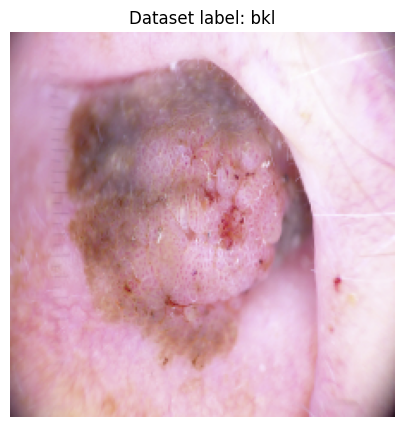


SUCCESS: Image pipeline test passed.


In [9]:

# STEP 8A: Verify that skin-lesion images load correctly

from pathlib import Path
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

WORK_DIR = Path("/kaggle/working")

train_path = WORK_DIR / "train.csv"
val_path = WORK_DIR / "validation.csv"
test_path = WORK_DIR / "test.csv"

# 1. Check that all split files exist
for path in [train_path, val_path, test_path]:
    if not path.exists():
        raise FileNotFoundError(
            f"{path.name} not found. Run Step 7 again."
        )

# 2. Load the split manifests
train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

# 3. Load one example image
sample = train_df.iloc[0]
image_path = Path(sample["image_path"])

if not image_path.exists():
    raise FileNotFoundError(
        f"Image not found: {image_path}"
    )

image_bytes = tf.io.read_file(str(image_path))
image = tf.io.decode_image(
    image_bytes,
    channels=3,
    expand_animations=False
)

image = tf.image.resize(image, (224, 224))
image = tf.cast(image, tf.uint8)

print("\nSample image ID:", sample["image_id"])
print("Label:", sample["dx"])
print("Image shape:", image.shape)

# 4. Display the image
plt.figure(figsize=(5, 5))
plt.imshow(image.numpy())
plt.title(f"Dataset label: {sample['dx']}")
plt.axis("off")
plt.show()

print("\nSUCCESS: Image pipeline test passed.")


In [10]:

# STEP 8B: Train the first skin-lesion classification model

from pathlib import Path
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight

# -----------------------------
# 1. Configuration
# -----------------------------
SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5

WORK_DIR = Path("/kaggle/working")
MODEL_DIR = WORK_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    "akiec", "bcc", "bkl", "df",
    "mel", "nv", "vasc"
]

tf.keras.utils.set_random_seed(SEED)

# -----------------------------
# 2. Load the prepared CSV files
# -----------------------------
train_df = pd.read_csv(WORK_DIR / "train.csv")
val_df = pd.read_csv(WORK_DIR / "validation.csv")

class_to_id = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

for frame in [train_df, val_df]:
    frame["label"] = frame["dx"].map(class_to_id)

    if frame["label"].isna().any():
        raise ValueError("Unexpected class label in CSV.")

    frame["label"] = frame["label"].astype("int32")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

# -----------------------------
# 3. Create the image pipeline
# -----------------------------
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

def make_dataset(frame, training=False):
    paths = frame["image_path"].astype(str).to_numpy()
    labels = frame["label"].to_numpy()

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(frame), 2000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)

# -----------------------------
# 4. Handle class imbalance
# -----------------------------
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASS_NAMES)),
    y=train_df["label"].to_numpy()
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("\nClass weights:")
print(class_weights)

# -----------------------------
# 5. Load pretrained MobileNetV2
# -----------------------------
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
], name="augmentation")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Initially freeze the pretrained feature extractor.
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

x = augmentation(inputs)

# MobileNetV2 expects pixels scaled to [-1, 1].
x = tf.keras.layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(x)

x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    len(CLASS_NAMES),
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# -----------------------------
# 6. Save the best checkpoint
# -----------------------------
model_path = MODEL_DIR / "skin_lesion_model.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
]

# -----------------------------
# 7. Train
# -----------------------------
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

# -----------------------------
# 8. Save class labels and history
# -----------------------------
with open(MODEL_DIR / "class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f, indent=2)

history_df = pd.DataFrame(history.history)
history_df.to_csv(
    WORK_DIR / "training_history.csv",
    index=False
)

print("\nTRAINING FINISHED")
print("Best model:", model_path)
print("Labels:", MODEL_DIR / "class_names.json")
print("History:", WORK_DIR / "training_history.csv")
print("\nDo not use training accuracy as proof of clinical reliability.")


Training images: 6380
Validation images: 1621

Class weights:
{0: 4.381868131868132, 1: 2.7702996092053844, 2: 1.292806484295846, 3: 12.152380952380952, 4: 1.3344488600711149, 5: 0.21200943741069353, 6: 11.25220458553792}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3756 - loss: 2.3879
Epoch 1: val_loss improved from None to 1.35360, saving model to /kaggle/working/models/skin_lesion_model.keras

Epoch 1: finished saving model to /kaggle/working/models/skin_lesion_model.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 256s 1s/step - accuracy: 0.4782 - loss: 1.6452 - val_accuracy: 0.5330 - val_loss: 1.3536
Epoch 2/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4530 - loss: 1.9231
Epoch 2: val_loss improved from 1.35360 to 1.17417, saving model to /kaggle/working/models/skin_lesion_model.keras

Epoch 2: finished saving model to /kaggle/working/models/skin_lesion_model.keras
200/200 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.5715 - loss: 1.3362 - val_accuracy: 0.6027 - val_loss: 1.1742
Epoch 3/5
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5261 - loss: 1.5455
Epoch 3: val_loss did not improve from 1.17417
200/200 ━━━━━━━━━━━━━━━━━━━━ 244s 1s/step - accuracy: 0.6152 - loss: 1.133

Test images: 2014
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
63/63 ━━━━━━━━━━━━━━━━━━━━ 55s 827ms/step - accuracy: 0.6639 - loss: 0.9494
63/63 ━━━━━━━━━━━━━━━━━━━━ 55s 854ms/step

FINAL HELD-OUT TEST RESULTS
---------------------------
Test loss: 0.9494
Test accuracy: 0.6639
Balanced accuracy: 0.4847

Classification report:
              precision    recall  f1-score   support

       akiec     0.1629    0.8529    0.2736        68
         bcc     0.6333    0.1900    0.2923       100
         bkl     0.4211    0.2341    0.3009       205
          df     0.0484    0.1364    0.0714        22
         mel     0.5047    0.2432    0.3283       222
          nv     0.8843    0.8247    0.8535      1363
        vasc     0.4189    0.9118    0.5741        34

    accuracy                         0.6639      2014
   macro avg     0.4391    0.4847    0.3849      2014
weighted avg     0.7415    0.6639    0.6786      2014



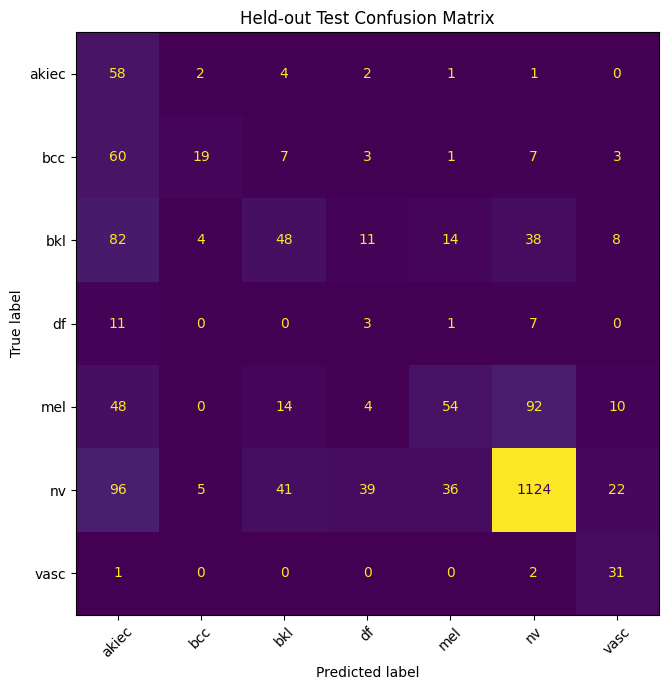


Saved confusion matrix: /kaggle/working/confusion_matrix.png
Saved predictions: /kaggle/working/test_predictions.csv

Melanoma test recall: 0.2432
This is a dataset-specific research metric, not evidence of clinical safety.


In [11]:

# STEP 9: Final evaluation on the held-out test set
# Do not train or tune the model using this test set.

from pathlib import Path
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
)

# -----------------------------
# 1. Locate saved files
# -----------------------------
WORK_DIR = Path("/kaggle/working")
MODEL_PATH = WORK_DIR / "models" / "skin_lesion_model.keras"
LABEL_PATH = WORK_DIR / "models" / "class_names.json"
TEST_PATH = WORK_DIR / "test.csv"

for path in [MODEL_PATH, LABEL_PATH, TEST_PATH]:
    if not path.exists():
        raise FileNotFoundError(
            f"Required file not found: {path}. "
            "Check that Steps 7 and 8B completed in this session."
        )

# -----------------------------
# 2. Load model and test manifest
# -----------------------------
model = tf.keras.models.load_model(MODEL_PATH)

with open(LABEL_PATH, "r") as file:
    CLASS_NAMES = json.load(file)

test_df = pd.read_csv(TEST_PATH)

if not {"image_path", "dx"}.issubset(test_df.columns):
    raise ValueError("test.csv must contain image_path and dx columns.")

class_to_id = {
    name: index for index, name in enumerate(CLASS_NAMES)
}

test_df = test_df[test_df["dx"].isin(CLASS_NAMES)].copy()
test_df["label"] = test_df["dx"].map(class_to_id).astype(int)

if test_df.empty:
    raise ValueError("No valid test records found.")

# Confirm test images still exist.
missing_paths = [
    p for p in test_df["image_path"].astype(str)
    if not Path(p).is_file()
]

if missing_paths:
    raise FileNotFoundError(
        f"{len(missing_paths)} test images are missing. "
        "Check the Kaggle dataset input."
    )

print("Test images:", len(test_df))
print("Classes:", CLASS_NAMES)

# -----------------------------
# 3. Create the test image pipeline
# -----------------------------
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def load_test_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

test_ds = tf.data.Dataset.from_tensor_slices(
    (
        test_df["image_path"].astype(str).to_numpy(),
        test_df["label"].to_numpy()
    )
)

test_ds = test_ds.map(
    load_test_image,
    num_parallel_calls=AUTOTUNE
).batch(BATCH_SIZE).prefetch(AUTOTUNE)

# -----------------------------
# 4. Evaluate the saved model
# -----------------------------
test_loss, test_accuracy = model.evaluate(
    test_ds, verbose=1
)

probabilities = model.predict(test_ds, verbose=1)
y_true = test_df["label"].to_numpy()
y_pred = np.argmax(probabilities, axis=1)

print("\nFINAL HELD-OUT TEST RESULTS")
print("---------------------------")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(
    "Balanced accuracy:",
    f"{balanced_accuracy_score(y_true, y_pred):.4f}"
)

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    zero_division=0,
    digits=4
))

# -----------------------------
# 5. Confusion matrix
# -----------------------------
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES)))
)

fig, ax = plt.subplots(figsize=(9, 7))

display = __import__(
    "sklearn.metrics",
    fromlist=["ConfusionMatrixDisplay"]
).ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

display.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

ax.set_title("Held-out Test Confusion Matrix")
plt.tight_layout()

FIGURE_PATH = WORK_DIR / "confusion_matrix.png"
plt.savefig(FIGURE_PATH, dpi=150, bbox_inches="tight")
plt.show()

# -----------------------------
# 6. Save test predictions
# -----------------------------
results = test_df[
    [c for c in ["image_id", "lesion_id", "dx"] if c in test_df.columns]
].copy()

results["true_class"] = [
    CLASS_NAMES[i] for i in y_true
]
results["predicted_class"] = [
    CLASS_NAMES[i] for i in y_pred
]
results["predicted_score"] = np.max(probabilities, axis=1)

results.to_csv(
    WORK_DIR / "test_predictions.csv",
    index=False
)

print("\nSaved confusion matrix:", FIGURE_PATH)
print("Saved predictions:", WORK_DIR / "test_predictions.csv")

# -----------------------------
# 7. Research-only melanoma recall
# -----------------------------
mel_id = class_to_id["mel"]
mel_true = (y_true == mel_id)
mel_pred = (y_pred == mel_id)

mel_recall = (
    np.sum(mel_true & mel_pred) / np.sum(mel_true)
    if np.sum(mel_true) else float("nan")
)

print(f"\nMelanoma test recall: {mel_recall:.4f}")
print(
    "This is a dataset-specific research metric, "
    "not evidence of clinical safety."
)


In [12]:

from pathlib import Path

root = Path("/kaggle/working")

print("Checking Kaggle working files...\n")

for path in root.rglob("*"):
    if path.is_file() and (
        path.suffix.lower() in {".keras", ".h5", ".csv", ".json"}
    ):
        print(path)

print("\nChecking available input files...\n")

input_root = Path("/kaggle/input")

if input_root.exists():
    for path in input_root.rglob("*"):
        if path.is_file() and path.suffix.lower() in {
            ".keras", ".h5"
        }:
            print(path)


Checking Kaggle working files...

/kaggle/working/test.csv
/kaggle/working/training_history.csv
/kaggle/working/test_predictions.csv
/kaggle/working/validation.csv
/kaggle/working/train.csv
/kaggle/working/models/skin_lesion_model.keras
/kaggle/working/models/class_names.json

Checking available input files...

/kaggle/input/notebooks/aymanalmadany/ham10000/saved_models/best_cnn_model.keras
/kaggle/input/notebooks/aymanalmadany/ham10000/saved_models/best_resnet_model.keras
/kaggle/input/notebooks/aymanalmadany/ham10000/saved_models/best_resnet_finetuned.keras


In [13]:

from pathlib import Path
import tensorflow as tf

root = Path("/kaggle/input")

model_files = [
    p for p in root.rglob("*.keras")
    if p.name in {
        "best_cnn_model.keras",
        "best_resnet_model.keras",
        "best_resnet_finetuned.keras",
    }
]

if not model_files:
    print("No candidate model files found.")
else:
    for path in model_files:
        print("\n" + "=" * 50)
        print("Model:", path.name)

        try:
            model = tf.keras.models.load_model(
                path, compile=False
            )

            print("Input shape:", model.input_shape)
            print("Output shape:", model.output_shape)
            print("Number of output classes:", model.output_shape[-1])

        except Exception as exc:
            print("Could not load model:", str(exc)[:500])



Model: best_cnn_model.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Number of output classes: 4

Model: best_resnet_model.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Number of output classes: 4

Model: best_resnet_finetuned.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 4)
Number of output classes: 4


In [14]:

# STEP 9C: Inspect model files and look for class-label mappings

from pathlib import Path
import json
import tensorflow as tf

ROOT = Path("/kaggle/input")

MODEL_NAMES = {
    "best_cnn_model.keras",
    "best_resnet_model.keras",
    "best_resnet_finetuned.keras",
}

models = [
    p for p in ROOT.rglob("*")
    if p.is_file() and p.name in MODEL_NAMES
]

if not models:
    print("No candidate models found.")
else:
    for path in models:
        print("\n" + "=" * 55)
        print("MODEL:", path.name)
        print("LOCATION:", path)

        try:
            model = tf.keras.models.load_model(
                path, compile=False
            )
            print("INPUT SHAPE:", model.input_shape)
            print("OUTPUT SHAPE:", model.output_shape)
            print("OUTPUT COUNT:", model.output_shape[-1])
        except Exception as e:
            print("MODEL LOAD ERROR:", str(e)[:300])

        # Inspect files near this model for label mappings.
        folder = path.parent
        print("\nFILES IN MODEL FOLDER:")

        for item in sorted(folder.iterdir()):
            if item.is_file():
                print(" ", item.name)

        print("\nPOSSIBLE LABEL MAPPINGS:")

        candidates = [
            p for p in folder.rglob("*")
            if p.is_file()
            and p.suffix.lower() in {
                ".json", ".txt", ".csv", ".yaml", ".yml"
            }
        ]

        found_mapping = False

        for file in candidates[:30]:
            try:
                content = file.read_text(
                    encoding="utf-8", errors="ignore"
                )[:5000]

                terms = [
                    "akiec", "bcc", "bkl", "df",
                    "mel", "nv", "vasc", "class_names",
                    "class_indices", "class_to_idx"
                ]

                if any(term in content.lower() for term in terms):
                    print("\nFILE:", file.name)
                    print(content[:1500])
                    found_mapping = True

            except Exception:
                pass

        if not found_mapping:
            print("No obvious label mapping found nearby.")

print("\nInspection complete.")



MODEL: best_cnn_model.keras
LOCATION: /kaggle/input/notebooks/aymanalmadany/ham10000/saved_models/best_cnn_model.keras
INPUT SHAPE: (None, 224, 224, 3)
OUTPUT SHAPE: (None, 4)
OUTPUT COUNT: 4

FILES IN MODEL FOLDER:
  best_cnn_model.keras
  best_resnet_finetuned.keras
  best_resnet_model.keras

POSSIBLE LABEL MAPPINGS:
No obvious label mapping found nearby.

MODEL: best_resnet_model.keras
LOCATION: /kaggle/input/notebooks/aymanalmadany/ham10000/saved_models/best_resnet_model.keras
INPUT SHAPE: (None, 224, 224, 3)
OUTPUT SHAPE: (None, 4)
OUTPUT COUNT: 4

FILES IN MODEL FOLDER:
  best_cnn_model.keras
  best_resnet_finetuned.keras
  best_resnet_model.keras

POSSIBLE LABEL MAPPINGS:
No obvious label mapping found nearby.

MODEL: best_resnet_finetuned.keras
LOCATION: /kaggle/input/notebooks/aymanalmadany/ham10000/saved_models/best_resnet_finetuned.keras
INPUT SHAPE: (None, 224, 224, 3)
OUTPUT SHAPE: (None, 4)
OUTPUT COUNT: 4

FILES IN MODEL FOLDER:
  best_cnn_model.keras
  best_resnet_fine

In [15]:

from pathlib import Path
import tensorflow as tf

root = Path("/kaggle/input")

model_names = [
    "best_cnn_model.keras",
    "best_resnet_model.keras",
    "best_resnet_finetuned.keras",
]

for name in model_names:
    matches = list(root.rglob(name))

    print("\n" + "=" * 40)
    print("Model:", name)

    if not matches:
        print("File not found")
        continue

    path = matches[0]

    try:
        model = tf.keras.models.load_model(
            path, compile=False
        )

        print("Input:", model.input_shape)
        print("Output:", model.output_shape)
        print("Number of classes:", model.output_shape[-1])

        if model.output_shape[-1] == 7:
            print("Seven outputs: candidate only.")
            print("Class order and preprocessing still need verification.")
        else:
            print("Not a seven-output model.")

    except Exception as error:
        print("Could not load:", str(error)[:300])



Model: best_cnn_model.keras
Input: (None, 224, 224, 3)
Output: (None, 4)
Number of classes: 4
Not a seven-output model.

Model: best_resnet_model.keras
Input: (None, 224, 224, 3)
Output: (None, 4)
Number of classes: 4
Not a seven-output model.

Model: best_resnet_finetuned.keras
Input: (None, 224, 224, 3)
Output: (None, 4)
Number of classes: 4
Not a seven-output model.


In [16]:

# STEP 10: Recreate our own seven-class model

from pathlib import Path
import json
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.utils.class_weight import compute_class_weight

WORK = Path("/kaggle/working")
MODEL_DIR = WORK / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_CSV = WORK / "train.csv"
VAL_CSV = WORK / "validation.csv"

for p in [TRAIN_CSV, VAL_CSV]:
    if not p.exists():
        raise FileNotFoundError(
            f"{p} is missing. Re-run Step 7 first."
        )

CLASS_NAMES = [
    "akiec", "bcc", "bkl", "df",
    "mel", "nv", "vasc"
]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}

train_df = pd.read_csv(TRAIN_CSV)
val_df = pd.read_csv(VAL_CSV)

for frame in [train_df, val_df]:
    frame["label"] = frame["dx"].map(CLASS_TO_ID)

    if frame["label"].isna().any():
        raise ValueError("Unexpected label in dataset.")

    frame["label"] = frame["label"].astype("int32")

# Ensure all seven classes are represented.
for name, frame in [("train", train_df), ("validation", val_df)]:
    missing = set(CLASS_NAMES) - set(frame["dx"].unique())
    if missing:
        raise ValueError(f"{name} split is missing: {missing}")

# Verify that image files are still available.
for frame in [train_df, val_df]:
    if not frame["image_path"].map(
        lambda p: Path(p).is_file()
    ).all():
        raise FileNotFoundError(
            "Some image files are unavailable. Re-run Step 7."
        )

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

# Image loading
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

def load_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(
        raw, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label

def make_dataset(frame, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (
            frame["image_path"].astype(str).values,
            frame["label"].values
        )
    )

    if training:
        ds = ds.shuffle(
            min(len(frame), 2000), seed=42
        )

    return (
        ds.map(load_image, num_parallel_calls=AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)

# Handle imbalanced categories.
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASS_NAMES)),
    y=train_df["label"].values
)
class_weights = {
    i: float(w) for i, w in enumerate(weights)
}

# Model architecture.
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
])

base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = tf.keras.layers.Rescaling(
    scale=1.0 / 127.5, offset=-1
)(x)
x = base(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
    7, activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_path = MODEL_DIR / "skin_lesion_model.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
]

# Save the label order explicitly.
with open(MODEL_DIR / "class_names.json", "w") as f:
    json.dump(CLASS_NAMES, f, indent=2)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    class_weight=class_weights,
    callbacks=callbacks
)

# Reload and verify the saved model.
saved_model = tf.keras.models.load_model(
    model_path, compile=False
)

print("\nTraining finished.")
print("Saved model:", model_path)
print("Output shape:", saved_model.output_shape)
print("Verified class order:", CLASS_NAMES)

assert saved_model.output_shape[-1] == len(CLASS_NAMES)
print("SUCCESS: Our model has seven outputs.")


Training images: 6380
Validation images: 1621
Epoch 1/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 0s 430ms/step - accuracy: 0.3795 - loss: 2.4221
Epoch 1: val_loss improved from None to 1.14570, saving model to /kaggle/working/models/skin_lesion_model.keras

Epoch 1: finished saving model to /kaggle/working/models/skin_lesion_model.keras
399/399 ━━━━━━━━━━━━━━━━━━━━ 216s 528ms/step - accuracy: 0.5052 - loss: 1.5498 - val_accuracy: 0.6095 - val_loss: 1.1457
Epoch 2/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 0s 431ms/step - accuracy: 0.5319 - loss: 1.6287
Epoch 2: val_loss did not improve from 1.14570
399/399 ━━━━━━━━━━━━━━━━━━━━ 213s 534ms/step - accuracy: 0.6187 - loss: 1.1464 - val_accuracy: 0.5737 - val_loss: 1.2670
Epoch 3/5
399/399 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step - accuracy: 0.5971 - loss: 1.3392
Epoch 3: val_loss did not improve from 1.14570
399/399 ━━━━━━━━━━━━━━━━━━━━ 259s 526ms/step - accuracy: 0.6547 - loss: 1.0081 - val_accuracy: 0.5472 - val_loss: 1.3264

Training finished.
Saved model: /kaggle/w

In [17]:

import socket
import urllib.request

print("Checking connection to TensorFlow model weights...")

try:
    address = socket.gethostbyname("storage.googleapis.com")
    print("DNS works:", address)

    url = "https://storage.googleapis.com/"
    request = urllib.request.urlopen(url, timeout=15)
    print("HTTPS connection works:", request.status)

except Exception as error:
    print("Connection failed:", repr(error))
    print("Check Kaggle Internet settings and retry.")


Checking connection to TensorFlow model weights...
DNS works: 108.177.98.207
Connection failed: <HTTPError 400: 'Bad Request'>
Check Kaggle Internet settings and retry.


In [18]:
import socket
print(socket.gethostbyname("storage.googleapis.com"))

173.194.43.207


In [19]:
import urllib.request

url = "https://storage.googleapis.com"
try:
    response = urllib.request.urlopen(url, timeout=15)
    print("Connection successful!")
    print("Status:", response.status)
except Exception as e:
    print("Connection failed:", repr(e))

Connection failed: <HTTPError 400: 'Bad Request'>


In [20]:
import urllib.request

url = (
    "https://storage.googleapis.com/"
    "tensorflow/keras-applications/mobilenet_v2/"
    "mobilenet_v2_weights_tf_dim_ordering_tf_kernels_1.0_224_no_top.h5"
)

try:
    request = urllib.request.Request(
        url, method="HEAD"
    )
    response = urllib.request.urlopen(request, timeout=20)
    print("Weights server reachable!")
    print("HTTP status:", response.status)
except Exception as e:
    print("Download test failed:", repr(e))

Weights server reachable!
HTTP status: 200


In [21]:
import os
import json
import tensorflow as tf

model_path = "/kaggle/working/models/skin_lesion_model.keras"
labels_path = "/kaggle/working/models/class_names.json"

print("Model exists:", os.path.exists(model_path))
print("Model size (MB):", round(os.path.getsize(model_path) / (1024 * 1024), 2))

model = tf.keras.models.load_model(model_path)
print("Model output shape:", model.output_shape)

if os.path.exists(labels_path):
    with open(labels_path, "r") as f:
        print("Class names:", json.load(f))
else:
    print("Class names file not found.")

Model exists: True
Model size (MB): 9.29
Model output shape: (None, 7)
Class names: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']


In [22]:
import os
import shutil

source = "/kaggle/working/models/skin_lesion_model.keras"
destination = "/kaggle/working/skin_lesion_model.keras"

shutil.copy2(source, destination)

print("Model copied:", os.path.exists(destination))
print("File size (MB):", round(os.path.getsize(destination) / (1024 * 1024), 2))
print("Ready to download from Kaggle output.")

Model copied: True
File size (MB): 9.29
Ready to download from Kaggle output.
